# General

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing import image

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# Data

In [3]:
(_, _), (x_test, y_test) = keras.datasets.mnist.load_data()
x_test = x_test.astype('float32') / 255.0
indices = np.array([np.flatnonzero(y_test == i)[0] for i in range(10)])

# New images

In [4]:
img_files = sorted(Path('images').glob('*.png'))
img_names = [fname.name for fname in img_files]
img_labels = np.array([int(fname.stem.split('_')[0]) for fname in img_files])

imgs = []
for fname in img_files:
    img = image.load_img(fname, color_mode='grayscale', target_size=(28, 28))
    imgs.append(image.img_to_array(img))
imgs = np.array(imgs)

In [5]:
imgs = (255.0 - imgs) / 255.0

# Recognition

In [6]:
def predict_calc_acc(model, imgs, labels, names, name):
    probabilities = model.predict(imgs, verbose=0)
    predictions = probabilities.argmax(axis=1)
    table = pd.DataFrame({
        'image': names,
        'class': labels,
        'prediction': predictions,
        'confidence': probabilities.max(axis=1)
    })
    table['correct'] = table['class'] == table['prediction']
    print(f"Accuracy on {name}: {table['correct'].mean():.2%}")
    display(table)

    rows = int(np.ceil(len(imgs) / 5))
    fig, axs = plt.subplots(rows, 5, figsize=(12, 2.7 * rows), squeeze=False)
    for ax in axs.flat:
        ax.axis('off')
    for i, (img, ax) in enumerate(zip(imgs, axs.flat)):
        row = table.iloc[i]
        ax.imshow(img.reshape(28, 28), cmap='gray')
        ax.set_title(
            f"{row['class']} --> {row['prediction']}",
            fontsize=9,
            color='green' if row['correct'] else 'red'
        )
    plt.tight_layout()
    plt.show()

    return table

Accuracy on part1_test: 100.00%


,image,class,prediction,confidence,correct
0,3,0,0,0.999846,True
1,2,1,1,0.994119,True
2,1,2,2,0.999868,True
3,18,3,3,0.952950,True
4,4,4,4,0.987079,True
5,8,5,5,0.990356,True
6,11,6,6,0.999988,True
7,0,7,7,0.999921,True
8,61,8,8,0.829294,True
9,7,9,9,0.992860,True


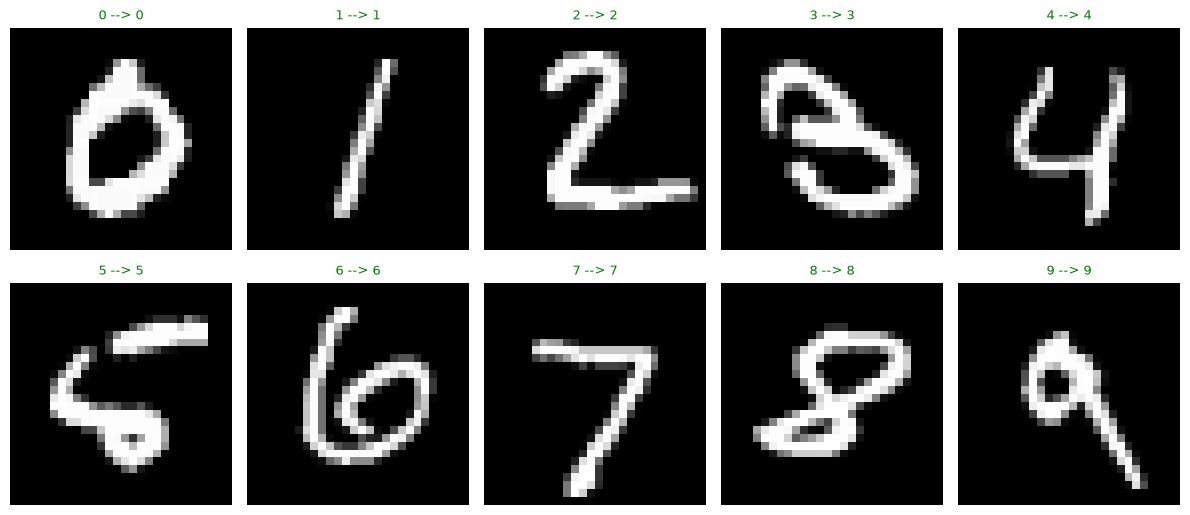

Accuracy on part1_new: 60.00%


,image,class,prediction,confidence,correct
0,0_uci.png,0,0,0.997556,True
1,1_uci.png,1,8,0.914539,False
2,2_uci.png,2,2,0.998264,True
3,3_uci.png,3,3,0.999965,True
4,4_uci.png,4,4,0.965127,True
5,5_uci.png,5,3,0.962096,False
6,6_uci.png,6,6,0.993413,True
7,7_uci.png,7,8,0.913856,False
8,8_uci.png,8,8,0.996937,True
9,9_uci.png,9,3,0.647603,False


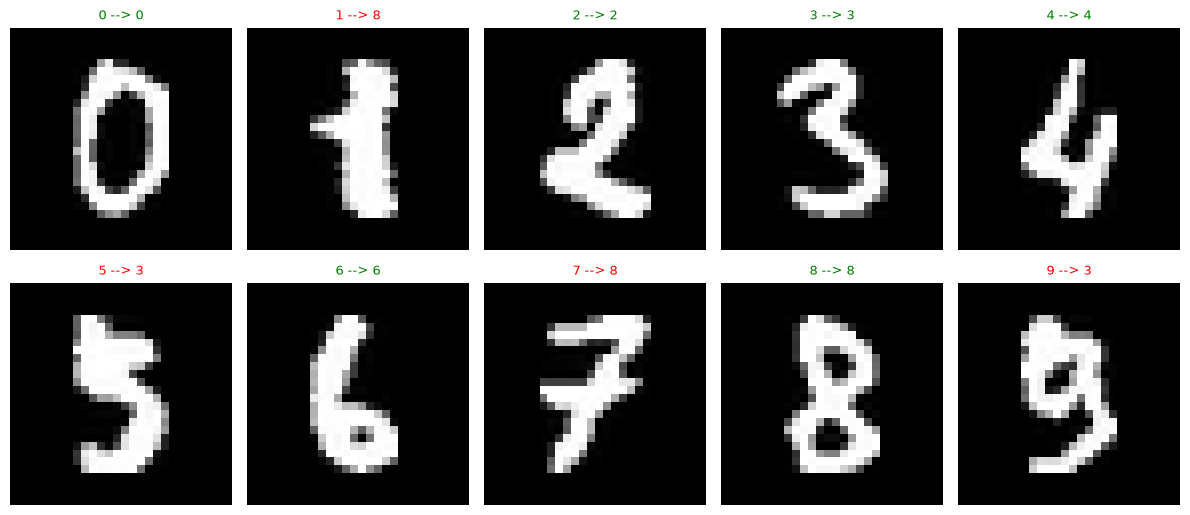

Accuracy on part2_test: 100.00%


,image,class,prediction,confidence,correct
0,3,0,0,0.999989,True
1,2,1,1,0.999719,True
2,1,2,2,0.999999,True
3,18,3,3,0.883746,True
4,4,4,4,0.999611,True
5,8,5,5,0.854677,True
6,11,6,6,0.999991,True
7,0,7,7,0.999979,True
8,61,8,8,0.995799,True
9,7,9,9,0.999851,True


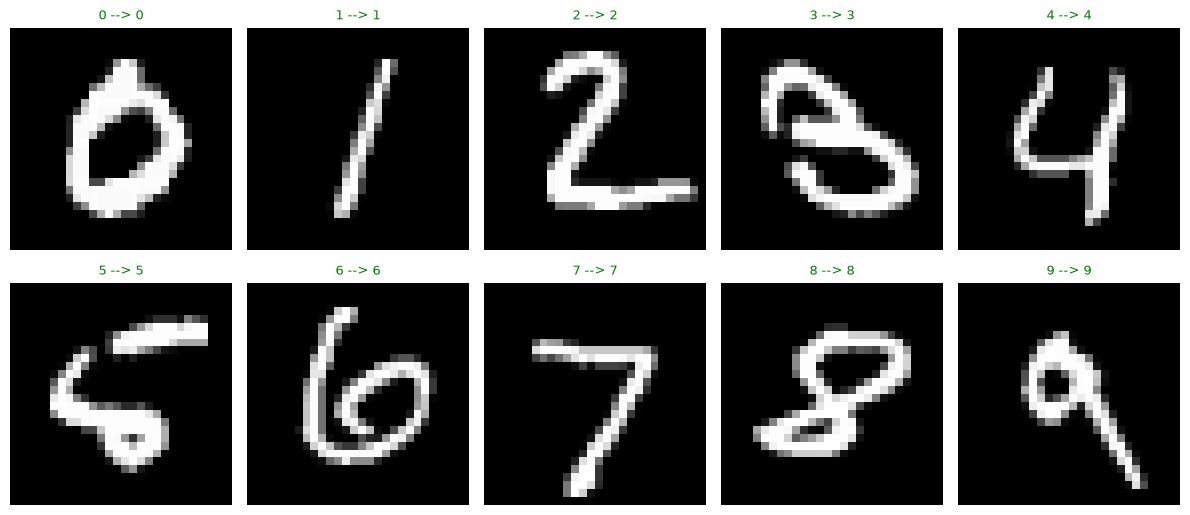

Accuracy on part2_new: 80.00%


,image,class,prediction,confidence,correct
0,0_uci.png,0,0,0.999829,True
1,1_uci.png,1,1,0.770064,True
2,2_uci.png,2,2,0.999643,True
3,3_uci.png,3,3,1.000000,True
4,4_uci.png,4,4,0.985894,True
5,5_uci.png,5,3,0.959757,False
6,6_uci.png,6,6,0.998190,True
7,7_uci.png,7,8,0.935334,False
8,8_uci.png,8,8,0.999864,True
9,9_uci.png,9,9,0.828608,True


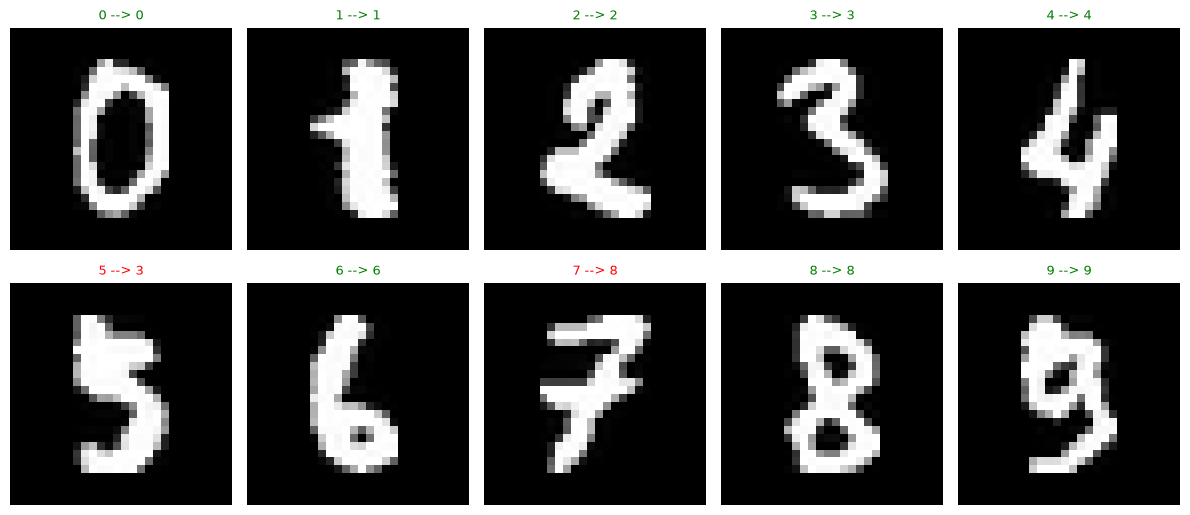

Accuracy on part3_test: 100.00%


,image,class,prediction,confidence,correct
0,3,0,0,0.999994,True
1,2,1,1,0.999854,True
2,1,2,2,1.000000,True
3,18,3,3,0.671740,True
4,4,4,4,0.999940,True
5,8,5,5,0.797823,True
6,11,6,6,1.000000,True
7,0,7,7,0.999996,True
8,61,8,8,0.999569,True
9,7,9,9,0.999576,True


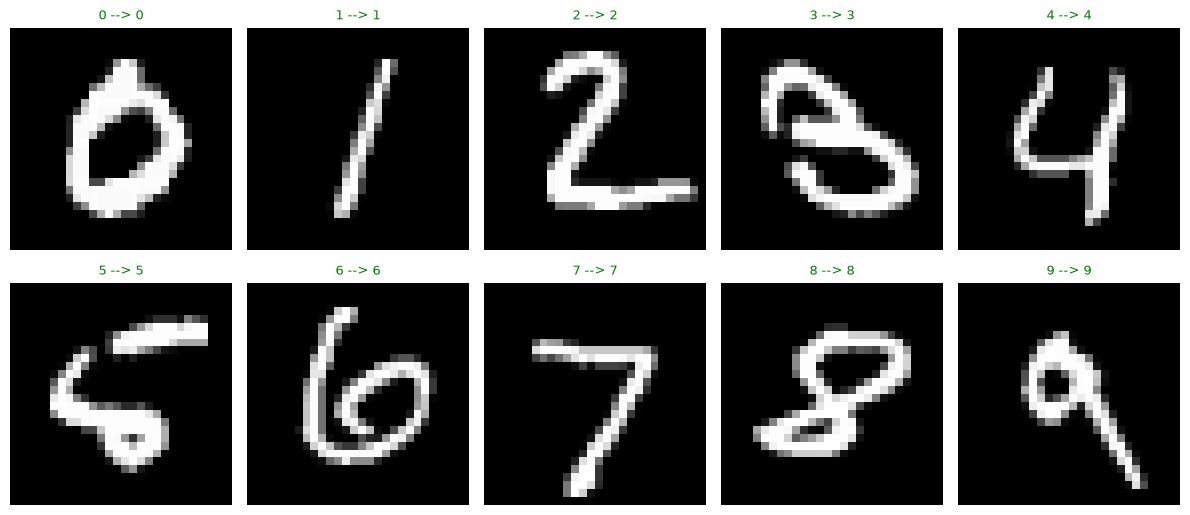

Accuracy on part3_new: 80.00%


,image,class,prediction,confidence,correct
0,0_uci.png,0,0,0.999968,True
1,1_uci.png,1,1,0.748615,True
2,2_uci.png,2,2,0.999930,True
3,3_uci.png,3,3,0.999998,True
4,4_uci.png,4,4,0.999855,True
5,5_uci.png,5,5,0.509209,True
6,6_uci.png,6,6,0.997772,True
7,7_uci.png,7,8,0.844265,False
8,8_uci.png,8,8,0.998615,True
9,9_uci.png,9,3,0.966393,False


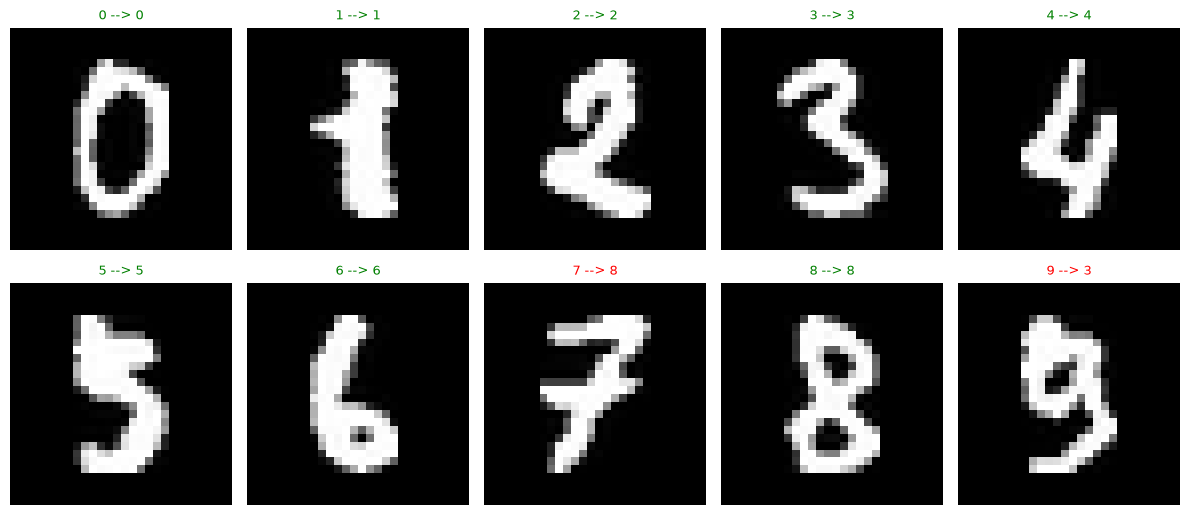

Accuracy on lab5_best_test: 100.00%


,image,class,prediction,confidence,correct
0,3,0,0,0.999983,True
1,2,1,1,0.999998,True
2,1,2,2,1.000000,True
3,18,3,3,0.969383,True
4,4,4,4,0.999991,True
5,8,5,5,0.998416,True
6,11,6,6,1.000000,True
7,0,7,7,1.000000,True
8,61,8,8,1.000000,True
9,7,9,9,0.999992,True


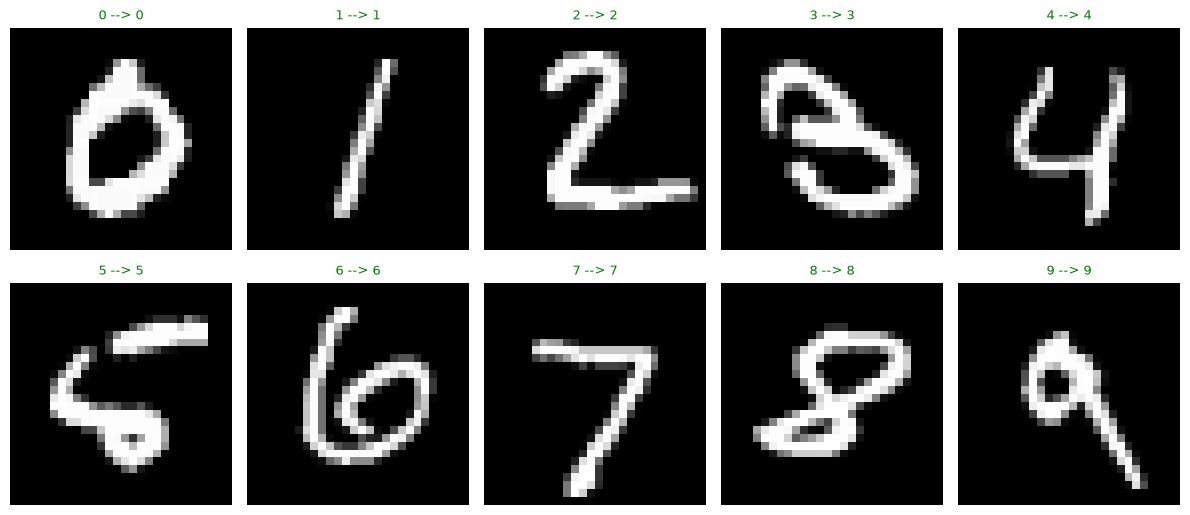

Accuracy on lab5_best_new: 90.00%


,image,class,prediction,confidence,correct
0,0_uci.png,0,0,1.000000,True
1,1_uci.png,1,1,0.939134,True
2,2_uci.png,2,2,0.999954,True
3,3_uci.png,3,3,1.000000,True
4,4_uci.png,4,4,0.999997,True
5,5_uci.png,5,5,0.989312,True
6,6_uci.png,6,6,0.999886,True
7,7_uci.png,7,7,0.906720,True
8,8_uci.png,8,8,1.000000,True
9,9_uci.png,9,3,0.596921,False


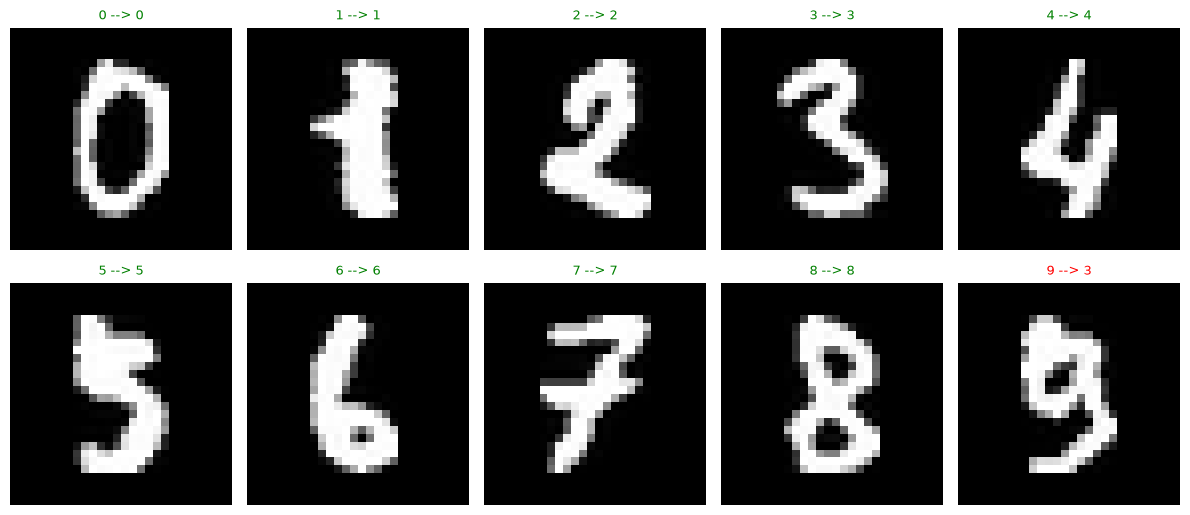

In [7]:
recognition = []
for name in ['part1', 'part2', 'part3', 'lab5_best']:
    model = keras.models.load_model(f'models/{name}.keras')
    if name == 'part1':
        test_imgs = x_test[indices]
        new_imgs = imgs[..., 0]
    elif name == 'part2':
        test_imgs = x_test[indices].reshape((-1, 784))
        new_imgs = imgs.reshape((-1, 784))
    else:
        test_imgs = x_test[indices, ..., np.newaxis]
        new_imgs = imgs

    test_results = predict_calc_acc(model, test_imgs, y_test[indices], indices, f'{name}_test')
    new_results = predict_calc_acc(model, new_imgs, img_labels, img_names, f'{name}_new')
    recognition.append({
        'name': name,
        'test_sample_accuracy': test_results['correct'].mean(),
        'new_accuracy': new_results['correct'].mean()
    })

# Results

In [8]:
recognition = pd.DataFrame(recognition)
display(recognition)

,name,test_sample_accuracy,new_accuracy
0,part1,1.0,0.6
1,part2,1.0,0.8
2,part3,1.0,0.8
3,lab5_best,1.0,0.9


# Summary

Збережені моделі завантажено без повторного навчання. Для перевірки взято перше тестове зображення кожної цифри та десять власних зображень.

| Model | Test images (10) | New images (10) |
|---|---:|---:|
| part1 | 100% | 60% |
| part2 | 100% | 80% |
| part3 | 100% | 80% |
| lab5_best | 100% | 90% |